# House Prices - EDA

## 1. Обзор данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
print(train.shape)
print(test.shape)

(1460, 81)
(1459, 80)


In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
num_cols = train.select_dtypes(include='number').columns.drop(['Id', 'SalePrice'])
cat_cols = train.select_dtypes(exclude='number').columns
print(len(num_cols), len(cat_cols))

36 43


### Выводы

- Обучающая выборка (1460 строк и 79 признаков), маленькая выборка, качество моделей будем оценивать кросс-валидацией
- Тестовые данные  1459 домов и 79 признаков
- Числовых признаков 36 (включая чиловые, которые переведем в категориальные)
- Категориальных признаков 43 - это больше половины, порядковые значения качества (`Ex/Gd/TA/Fa/Po`) нужно закодировать по порядку, остальное через one-hot 

## 2. Пропуски

In [5]:
missing_count = train.isna().sum()
missing_share = train.isna().mean()
missing_train = pd.DataFrame({'count': missing_count, 'share': missing_share})
missing_train = missing_train[missing_train['count'] > 0].sort_values('count', ascending=False)


In [6]:
missing_train

,count,share
PoolQC,1453,0.995205
MiscFeature,1406,0.963014
Alley,1369,0.937671
Fence,1179,0.807534
MasVnrType,872,0.597260
FireplaceQu,690,0.472603
LotFrontage,259,0.177397
GarageType,81,0.055479
GarageYrBlt,81,0.055479
GarageFinish,81,0.055479


In [7]:
missing_count = test.isna().sum()
missing_share = test.isna().mean()
missing_test = pd.DataFrame({'count': missing_count, 'share': missing_share})
missing_test = missing_test[missing_test['count'] > 0].sort_values('count', ascending=False)

In [8]:
missing_test

,count,share
PoolQC,1456,0.997944
MiscFeature,1408,0.965045
Alley,1352,0.926662
Fence,1169,0.801234
MasVnrType,894,0.612748
FireplaceQu,730,0.500343
LotFrontage,227,0.155586
GarageCond,78,0.053461
GarageYrBlt,78,0.053461
GarageQual,78,0.053461


In [9]:
set(missing_test.index) - set(missing_train.index)

{'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtFullBath',
 'BsmtHalfBath',
 'BsmtUnfSF',
 'Exterior1st',
 'Exterior2nd',
 'Functional',
 'GarageArea',
 'GarageCars',
 'KitchenQual',
 'MSZoning',
 'SaleType',
 'TotalBsmtSF',
 'Utilities'}

### Вывод 

Пропуски в данных делятся на две принципиально разные группы. Для большинства признаков `NA` в описании данных означаает отсутствие объекта, а не потерю информации.


| Признаки | Тип пропуска | Решение |
|---|---|---|
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond` | Нет гаража (81 дом) | `"None"` |
| `GarageYrBlt` | Нет гаража | Решим при предобработке |
| `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2` | Нет подвала (37 домов) | `"None"` |
| `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu` | Нет объекта | `"None"` |
| `MasVnrType` | В основном нет облицовки | `"None"` |
| `MasVnrArea` | Настоящий пропуск (8 домов) | `0` |
| `LotFrontage` | Настоящий пропуск (17.7%) | Решим при предобработке |
| `Electrical` | Настоящий пропуск (1 дом) | Мода |

- `MasVnrType`: pandas 3 читает значение `None` как пропуск, поэтому пропусков 872 вместо: 8.
- В `test` пропуски есть еще у 15 признаков. Обработку строим по смыслу признака, а не по наличию пропусков в `train`.



## 3. Целевая переменная

In [10]:
train['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [11]:
train['SalePrice'].skew()

np.float64(1.8828757597682129)

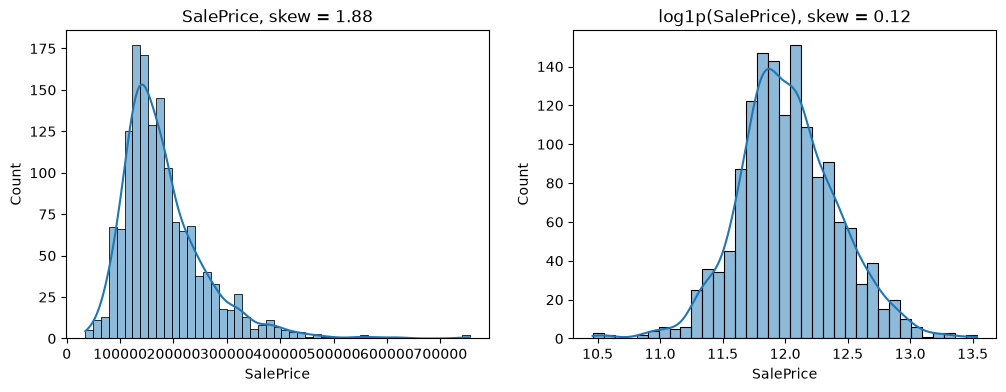

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(train['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title(f'SalePrice, skew = {train['SalePrice'].skew():.2f}')

log_price = np.log1p(train['SalePrice'])
sns.histplot(log_price, kde=True, ax=axes[1])
axes[1].set_title(f'log1p(SalePrice), skew = {log_price.skew():.2f}')

plt.show()

 


### Вывод 

- Распределение `SalePrice` сильно скошено вправо (skew = 1.88): большинство домов недорогие, нескольков  дорогих образуют длинный хвост.
- После `log1p` скошенность снизилась до 0.12, распределение стало почти симметричным.
- Метрика соревнования - RMSE между логарифмами цен, поэтому модель обучаем на `log1p(SalePrice)`: она оптимизирует ту же величину, по которой ее оценивают. Для результатов возвращаем в доллары через `np.expm1`.

## 4. Выбросы

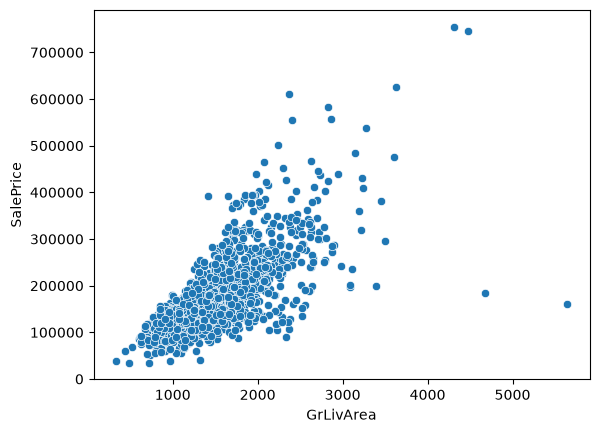

In [13]:
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice')
plt.show()

In [ ]:
train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]

## 5. Связь признаков с ценой

## 6. Итоговыевыводы для предобработки